# Phase 1, Part B: Supervised Learning

This notebook builds and compares two supervised classification models for our early-warning academic advisory system.

- **Task:** predict each student's outcome (**Dropout**, **Enrolled**, or **Graduate**) at the end of the 1st semester.
- **Data:** `Dataset/preprocessed_data.csv`, created in `Phase1_Data_Exploration.ipynb` (102 features, shared train/test split in the `split` column: 3,539 training and 885 test students).
- **Shared rules for both models:** the same train/test split, `random_state=42`, 5-fold stratified cross-validation on the training set, macro F1 as the tuning metric, and `class_weight="balanced"` for the class imbalance.

**Notebook structure:**
- Model 1: Random Forest
- Model 2: Logistic Regression
- 3. Model Evaluation & Comparison (shared evaluation function, metrics, confusion matrices, cross-validation, misclassification analysis, trade-offs)
- 4. Conclusion: Best Model Selection & Reasoning
- 5. Next Steps for Phase 2 Integration

## Model 1: Random Forest Classifier

### 1. Model Selection Rationale
* **Dataset Characteristics**: The dataset contains a mix of numerical and categorical features related to student demographics, academic background, and social-economic factors. Random Forest handles heterogeneous data exceptionally well without requiring extensive feature scaling.
* **Problem Type**: This is a multiclass classification problem aimed at predicting student outcomes (Dropout, Enrolled, Graduate). Random Forest natively supports multi-class classification and handles complex non-linear relationships.
* **Strengths**:
  * High accuracy and robustness against overfitting through ensemble learning (bagging).
  * Built-in feature importance evaluation, which helps leadership identify key factors influencing student success.
  * Less sensitive to outliers and missing values compared to other algorithms.

* **Weaknesses:**
  * Reduced Interpretability: Random Forest combines multiple decision trees, making its overall predictions more difficult to explain than those of simpler models.
  * Computational Cost: Training and tuning multiple trees can require more time and computational resources, especially when testing many hyperparameter combinations.
  * Overfitting Risk: Although ensemble learning helps control overfitting, the model can still overfit depending on its depth and other settings.

**Feature Importance Limitations:** Feature importance scores indicate which features contribute to the model's predictions, but they do not establish causation.  

Baseline Accuracy: 0.7243
Baseline Macro F1: 0.6627

Best Parameters: {'max_depth': 20, 'min_samples_split': 10, 'n_estimators': 100}
Best Mean CV Macro F1: 0.6991

Tuned Test Accuracy: 0.7254
Tuned Test Macro F1: 0.6778

Classification Report:
              precision    recall  f1-score   support

     Dropout     0.7743    0.7007    0.7357       284
    Enrolled     0.4175    0.5409    0.4712       159
    Graduate     0.8460    0.8077    0.8264       442

    accuracy                         0.7254       885
   macro avg     0.6793    0.6831    0.6778       885
weighted avg     0.7460    0.7254    0.7335       885



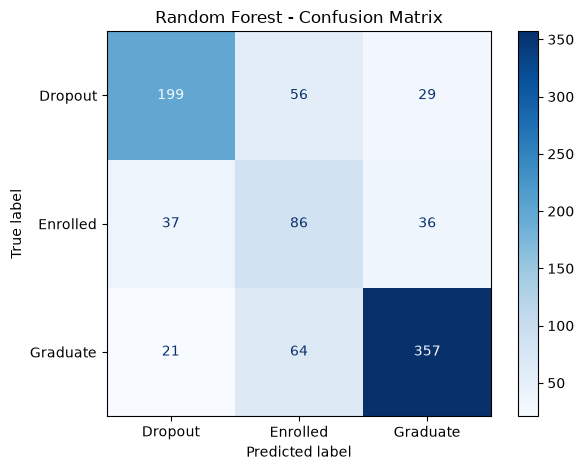

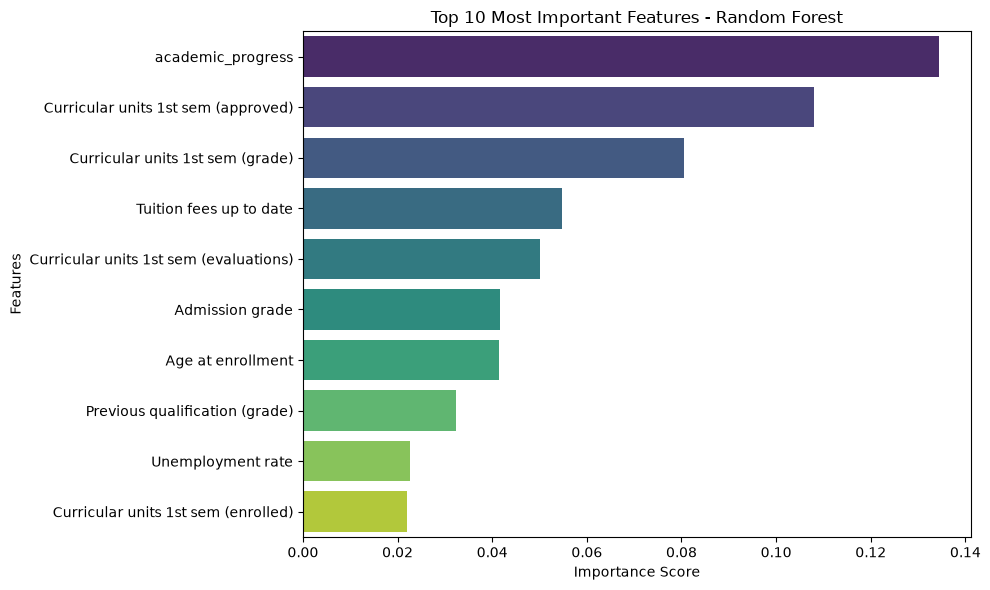

                               Feature  Importance
                     academic_progress    0.134506
   Curricular units 1st sem (approved)    0.108058
      Curricular units 1st sem (grade)    0.080454
               Tuition fees up to date    0.054725
Curricular units 1st sem (evaluations)    0.050017
                       Admission grade    0.041679
                     Age at enrollment    0.041522
        Previous qualification (grade)    0.032434
                     Unemployment rate    0.022668
   Curricular units 1st sem (enrolled)    0.022031


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Load the preprocessed dataset (same path style as Model 2)
df = pd.read_csv("Dataset/preprocessed_data.csv")

# 2. Use the shared train/test split
train_data = df[df["split"] == "train"]
test_data = df[df["split"] == "test"]

X_train = train_data.drop(columns=["Target", "split"])
y_train = train_data["Target"]
X_test = test_data.drop(columns=["Target", "split"])
y_test = test_data["Target"]

labels = [0, 1, 2]
names = ["Dropout", "Enrolled", "Graduate"]

# 3. Baseline Random Forest (class_weight handles the imbalance)
rf_base = RandomForestClassifier(class_weight="balanced", random_state=42)
rf_base.fit(X_train, y_train)
y_pred_base = rf_base.predict(X_test)

print("Baseline Accuracy:", round(accuracy_score(y_test, y_pred_base), 4))
print("Baseline Macro F1:", round(f1_score(y_test, y_pred_base, average="macro"), 4))

# 4. Hyperparameter tuning (same 5-fold stratified CV as Model 2)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5, 10]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(class_weight="balanced", random_state=42),
    param_grid=param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    refit=True
)
grid_search.fit(X_train, y_train)

print("\nBest Parameters:", grid_search.best_params_)
print("Best Mean CV Macro F1:", round(grid_search.best_score_, 4))

# 5. Evaluate the tuned model on the test set
best_rf = grid_search.best_estimator_
y_pred_tuned = best_rf.predict(X_test)

print("\nTuned Test Accuracy:", round(accuracy_score(y_test, y_pred_tuned), 4))
print("Tuned Test Macro F1:", round(f1_score(y_test, y_pred_tuned, average="macro"), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test, y_pred_tuned,
        labels=labels, target_names=names,
        digits=4, zero_division=0
    )
)

# 6. Confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_tuned, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=names)
disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

# 7. Top 10 feature importances
importances = best_rf.feature_importances_
feature_imp_df = (
    pd.DataFrame({"Feature": X_train.columns, "Importance": importances})
    .sort_values(by="Importance", ascending=False)
    .head(10)
)


plt.figure(figsize=(10, 6))
sns.barplot(
    x="Importance", y="Feature", data=feature_imp_df,
    hue="Feature", palette="viridis", legend=False
)
plt.title("Top 10 Most Important Features - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

print(feature_imp_df.to_string(index=False))

### Random Forest: Results & Feature Importance

**Tuning:** in the committed run, tuning improved the test macro F1 from 0.663 (baseline) to 0.678, with accuracy staying at about 72.5%. The best settings were 100 trees, a maximum depth of 20, and a minimum of 10 samples to split a node. Limiting the depth and requiring more samples per split makes the trees simpler, which reduces overfitting. The full tuning table is shown in Section 3.1.

**Per-class results:** Graduate is predicted best (F1 about 0.83), followed by Dropout (about 0.74). Enrolled is the weakest class (F1 about 0.47), which matches the overlap seen in the exploratory analysis.

**Feature importance:** the most important features are `academic_progress`, the number of approved units and the grade in the 1st semester, and tuition fees status, followed by the number of 1st-semester evaluations, admission grade, and age at enrollment. This agrees with the exploratory analysis. Two cautions apply:
- `academic_progress` is calculated from approved and enrolled units, so these related features share their importance, and the ranking between them should not be over-interpreted.
- Importance scores show which features the model relies on, not the direction of the effect, and they do not prove causation.

*If the notebook is re-run with different library versions, check that these numbers still match the printed output.*

## Model 2: Logistic Regression

### 1. Model Selection Rationale

**Dataset Characteristics:**
The dataset contains numerical and categorical features related to students' demographics, academic backgrounds, and socioeconomic circumstances. The original features require preprocessing before being used by Logistic Regression. After encoding categorical variables and scaling numerical features, the resulting dataset can be used to train the model. The dataset has three target classes: Dropout, Enrolled, and Graduate, with an unequal distribution across classes.

**Problem Type:**
This is a multiclass classification problem in which the model predicts one of three student academic outcomes: Dropout, Enrolled, or Graduate. Logistic Regression supports multiclass classification and can estimate the probabilities of each outcome.

**Strengths:**
- **Interpretability:** Model coefficients help explain how input features are associated with the predicted outcomes, making the model easier to interpret than more complex approaches in many cases.
- **Computational Efficiency:** Logistic Regression is relatively lightweight and efficient to train, making it suitable for this dataset.
- **Multiclass Classification:** It can handle the project's three outcome classes using an appropriate multiclass strategy.
- **Baseline for Comparison:** It provides a useful model to compare against Random Forest, which can capture more complex nonlinear relationships.

**Weaknesses:**
- **Linear Decision Boundaries:** Logistic Regression may struggle to capture complex nonlinear relationships between student characteristics and academic outcomes.
- **Preprocessing Requirements:** Categorical features must be encoded, and scaling numerical features is generally beneficial for reliable regularization and optimization.
- **Class Imbalance:** The unequal distribution of student outcomes may affect performance on minority classes. Class weighting and macro F1-score can help address and evaluate this issue, respectively.
- **Feature Relationships:** Strong correlations between input features can make individual coefficients harder to interpret.

**Selection Justification:**
Logistic Regression was selected because it offers an efficient and relatively interpretable approach to multiclass classification. Its limitations also make it a useful counterpart to Random Forest, allowing the project to evaluate two different modeling approaches using the same dataset and evaluation metrics.

In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Load the preprocessed dataset
df = pd.read_csv("Dataset/preprocessed_data.csv")

# 2. Use the shared train/test split
train_data = df[df["split"] == "train"]
test_data = df[df["split"] == "test"]

# 3. Separate input features from the target
X_train = train_data.drop(columns=["Target", "split"])
y_train = train_data["Target"]

X_test = test_data.drop(columns=["Target", "split"])
y_test = test_data["Target"]

# 4. Check the data before training
print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)
print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

# 5. Define five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 6. Define the hyperparameters to test
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100]
}

# 7. Create the model and search for the best hyperparameter
log_reg = LogisticRegression(
    max_iter=3000,
    class_weight="balanced",
    random_state=42
)

grid_search_lr = GridSearchCV(
    estimator=log_reg,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

# 8. Train and tune using the training set only
grid_search_lr.fit(X_train, y_train)

# 9. Retrieve the best model
best_lr = grid_search_lr.best_estimator_

print("\nBest Parameters:", grid_search_lr.best_params_)
print("Best Mean CV Macro F1:", round(grid_search_lr.best_score_, 4))


Training set shape: (3539, 102)
Test set shape: (885, 102)

Training class distribution:
Target
0    1137
1     635
2    1767
Name: count, dtype: int64

Best Parameters: {'C': 1}
Best Mean CV Macro F1: 0.6846


Logistic Regression Test Accuracy: 0.6972
Logistic Regression Test Macro F1: 0.6601

Classification Report:
              precision    recall  f1-score   support

     Dropout     0.7890    0.6585    0.7179       284
    Enrolled     0.3831    0.5975    0.4668       159
    Graduate     0.8375    0.7579    0.7957       442

    accuracy                         0.6972       885
   macro avg     0.6699    0.6713    0.6601       885
weighted avg     0.7403    0.6972    0.7116       885



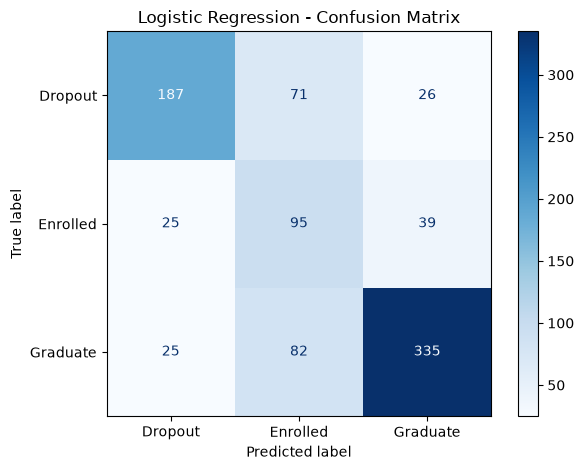

In [3]:

# 10. Predict the test set
y_pred_lr = best_lr.predict(X_test)

# 11. Calculate test accuracy
test_accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Test Accuracy:",
      round(test_accuracy_lr, 4))

# test macro F1
print("Logistic Regression Test Macro F1:",
      round(f1_score(y_test, y_pred_lr, average="macro"), 4))

# 12. Print precision, recall, and F1-score for each class
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_lr,
        labels=[0, 1, 2],
        target_names=["Dropout", "Enrolled", "Graduate"],
        digits=4,
        zero_division=0
    )
)

# 13. Plot the confusion matrix
cm_lr = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["Dropout", "Enrolled", "Graduate"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()


In [4]:
# 14. Compare the hyperparameter tuning results
cv_results_lr = pd.DataFrame(grid_search_lr.cv_results_)

tuning_results_lr = cv_results_lr[
    [
        "param_C",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
].sort_values("rank_test_score")

tuning_results_lr = tuning_results_lr.rename(
    columns={
        "param_C": "C",
        "mean_test_score": "Mean CV Macro F1",
        "std_test_score": "CV Standard Deviation",
        "rank_test_score": "Rank"
    }
)

print(tuning_results_lr.to_string(index=False))


     C  Mean CV Macro F1  CV Standard Deviation  Rank
  1.00          0.684628               0.010198     1
  0.10          0.684475               0.012796     2
100.00          0.679625               0.013704     3
 10.00          0.677989               0.012344     4
  0.01          0.664537               0.015422     5


### Logistic Regression: Results

**Tuning:** in the committed run, `C = 1` and `C = 0.1` were almost tied (mean CV macro F1 of about 0.685 for both), while `C = 0.01` was clearly worse (about 0.665), which shows that too much regularization makes the model too simple. Because the top two values are so close, the selected `C` can change between library versions (see Section 3.1).

**Test results:** accuracy of about 69.7% and macro F1 of about 0.660. For Enrolled, this model has a higher recall than Random Forest (about 0.60 vs. 0.54) but a lower precision (about 0.38): the class weights make the model predict Enrolled often, and many of those predictions are wrong. A full comparison with Random Forest follows in Section 3.

*If the notebook is re-run with different library versions, check that these numbers still match the printed output.*

## 3. Model Evaluation & Comparison

This section evaluates both tuned models with **exactly the same protocol**, using one shared evaluation function:

| Check | What it tells us |
|---|---|
| Accuracy | Share of test students classified correctly (can look good just by favouring the biggest class) |
| Precision, Recall, F1 per class | How trustworthy the predictions for each class are (precision) and how many real students of that class we catch (recall) |
| Macro F1 | Average F1 over the three classes, each class counting equally. **Our main yardstick**, because *Enrolled* is only about 18% of the students and accuracy hides weak performance on it |
| Confusion matrix | Exactly which classes get mixed up |
| 5-fold stratified cross-validation | How stable the result is when the training data is re-split (the test set is not touched) |
| ROC-AUC (one-vs-rest, macro) | Supplementary only: the handbook requires ROC-AUC for binary problems, ours has three classes |

**Rules followed:** both models are evaluated on the same 885 test students; the test set was never used for tuning; the cross-validation uses the same splitter (`random_state=42`) for both models.


In [5]:
# ============================================================
# MODEL EVALUATION & COMPARISON - shared setup
# Both tuned models (best_rf, best_lr) are evaluated on the SAME
# held-out test set, with the SAME 5-fold splitter and random_state.
# ============================================================
import time, io
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.stats import binomtest
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, roc_auc_score
)

RANDOM_STATE = 42
CLASS_IDS = [0, 1, 2]
CLASS_NAMES = ["Dropout", "Enrolled", "Graduate"]
MODEL_COLORS = {"Random Forest": "#2a78d6", "Logistic Regression": "#eb6834"}

# Output folders required by the project structure
results_dir = Path("Supervised_Learning/evaluation_results")
plots_dir = Path("Supervised_Learning/plots")
models_dir = Path("Supervised_Learning/models")
for folder in (results_dir, plots_dir, models_dir):
    folder.mkdir(parents=True, exist_ok=True)

# Plot style: light grid, no top/right frame
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12,
})

# One shared train/test definition for both models
df_eval = pd.read_csv("Dataset/preprocessed_data.csv")
train_part = df_eval[df_eval["split"] == "train"]
test_part = df_eval[df_eval["split"] == "test"]
X_train = train_part.drop(columns=["Target", "split"])
y_train = train_part["Target"]
X_test = test_part.drop(columns=["Target", "split"])
y_test = test_part["Target"]

# The two tuned models trained in the sections above
models = {"Random Forest": best_rf, "Logistic Regression": best_lr}

# Safety checks: both models were trained on exactly these columns
for name, model in models.items():
    assert list(model.feature_names_in_) == list(X_train.columns), f"{name}: feature mismatch"

print(f"Train: {X_train.shape}  |  Test: {X_test.shape}  |  features: {X_train.shape[1]}")
print("Test class counts:", dict(zip(CLASS_NAMES, y_test.value_counts().sort_index().tolist())))
print("Tuned settings:")
print("  Random Forest      :", best_rf.get_params()["n_estimators"], "trees, max_depth =",
      best_rf.get_params()["max_depth"], ", min_samples_split =", best_rf.get_params()["min_samples_split"])
print("  Logistic Regression: C =", best_lr.get_params()["C"])

Train: (3539, 102)  |  Test: (885, 102)  |  features: 102
Test class counts: {'Dropout': 284, 'Enrolled': 159, 'Graduate': 442}
Tuned settings:
  Random Forest      : 100 trees, max_depth = 20 , min_samples_split = 10
  Logistic Regression: C = 1


In [6]:
# ---------- One shared evaluation function (used for BOTH models) ----------
def evaluate_model(name, model, X_eval, y_eval, verbose=True):
    """Accuracy, precision/recall/F1 (per class + macro), confusion matrix, ROC-AUC (OvR)."""
    y_pred = model.predict(X_eval)
    proba = model.predict_proba(X_eval)

    p, r, f, s = precision_recall_fscore_support(
        y_eval, y_pred, labels=CLASS_IDS, zero_division=0
    )
    per_class = pd.DataFrame({
        "Model": name, "Class": CLASS_NAMES,
        "Precision": p, "Recall": r, "F1": f, "Support": s,
    })
    overall = {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, y_pred),
        "Macro Precision": p.mean(),
        "Macro Recall": r.mean(),
        "Macro F1": f.mean(),
        "Weighted F1": np.average(f, weights=s),
        # supplementary: one-vs-rest ROC-AUC (the handbook requires ROC-AUC only for binary problems)
        "ROC-AUC (OvR macro)": roc_auc_score(y_eval, proba, multi_class="ovr", average="macro"),
    }
    cm = confusion_matrix(y_eval, y_pred, labels=CLASS_IDS)

    if verbose:
        print(f"===== {name} =====")
        print(classification_report(y_eval, y_pred, labels=CLASS_IDS,
                                    target_names=CLASS_NAMES, digits=4, zero_division=0))
    return {"name": name, "y_pred": y_pred, "proba": proba,
            "overall": overall, "per_class": per_class, "cm": cm}


# ---------- One shared 5-fold cross-validation function ----------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cross_validate_model(name, model, X, y, cv):
    """5-fold stratified CV on the TRAINING set only (the test set stays untouched)."""
    scores = cross_validate(
        clone(model), X, y, cv=cv, n_jobs=-1,
        scoring={"Accuracy": "accuracy", "Macro Precision": "precision_macro",
                 "Macro Recall": "recall_macro", "Macro F1": "f1_macro"},
    )
    folds = pd.DataFrame({
        "Model": name, "Fold": range(1, cv.get_n_splits() + 1),
        **{m: scores[f"test_{m}"] for m in ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]},
    })
    return folds

### 3.1 Hyperparameter tuning recap

A short recap of the two grid searches run above, so the tuning process and results are visible in one place before the models are compared.

In [7]:
# ---------- Hyperparameter tuning recap (results come from the grid searches above) ----------
rf_tuning = (pd.DataFrame(grid_search.cv_results_)
             [["param_n_estimators", "param_max_depth", "param_min_samples_split",
               "mean_test_score", "std_test_score", "rank_test_score"]]
             .rename(columns={"param_n_estimators": "n_estimators", "param_max_depth": "max_depth",
                              "param_min_samples_split": "min_samples_split",
                              "mean_test_score": "Mean CV Macro F1", "std_test_score": "CV Std",
                              "rank_test_score": "Rank"})
             .sort_values("Rank").head(5))
print("Random Forest: 27 combinations tried (3 x 3 x 3) - top 5 by mean CV macro F1")
print(rf_tuning.round(4).to_string(index=False))
print("\nLogistic Regression: 5 values of C tried - best =", grid_search_lr.best_params_,
      "| mean CV macro F1 =", round(grid_search_lr.best_score_, 4))
print("\nBoth searches used the TRAINING set only, 5-fold stratified CV (random_state=42), "
      "scoring = macro F1, class_weight = 'balanced'.")

Random Forest: 27 combinations tried (3 x 3 x 3) - top 5 by mean CV macro F1
 n_estimators max_depth  min_samples_split  Mean CV Macro F1  CV Std  Rank
          100        20                 10            0.6991  0.0062     1
           50        20                 10            0.6980  0.0091     2
          200      None                 10            0.6976  0.0053     3
          100      None                 10            0.6970  0.0016     4
          200      None                  5            0.6948  0.0143     5

Logistic Regression: 5 values of C tried - best = {'C': 1} | mean CV macro F1 = 0.6846

Both searches used the TRAINING set only, 5-fold stratified CV (random_state=42), scoring = macro F1, class_weight = 'balanced'.


**What this means:** the Random Forest results are close across many settings, so the model is not very sensitive to the exact hyperparameters. For Logistic Regression the two best values of `C` are almost tied (the difference between them is far smaller than the fold-to-fold spread), so the "best" `C` can change slightly between machines or library versions. This is why every number in this section is generated by code and not typed by hand.

### 3.2 Test-set metrics

Both tuned models are run through the same `evaluate_model` function on the held-out test set.

In [8]:
# ---------- Run the SAME evaluation on both tuned models ----------
results = {name: evaluate_model(name, model, X_test, y_test) for name, model in models.items()}

# Overall comparison table (test set)
summary_df = pd.DataFrame([res["overall"] for res in results.values()]).set_index("Model")
summary_df.round(4).to_csv(results_dir / "test_metrics_summary.csv")

# Per-class comparison table (test set)
per_class_df = pd.concat([res["per_class"] for res in results.values()], ignore_index=True)
per_class_df.round(4).to_csv(results_dir / "test_metrics_per_class.csv", index=False)

print("OVERALL TEST-SET METRICS")
display_summary = summary_df.round(4)
print(display_summary.to_string())
print("\nPER-CLASS TEST-SET METRICS")
print(per_class_df.round(4).to_string(index=False))

===== Random Forest =====
              precision    recall  f1-score   support

     Dropout     0.7743    0.7007    0.7357       284
    Enrolled     0.4175    0.5409    0.4712       159
    Graduate     0.8460    0.8077    0.8264       442

    accuracy                         0.7254       885
   macro avg     0.6793    0.6831    0.6778       885
weighted avg     0.7460    0.7254    0.7335       885

===== Logistic Regression =====
              precision    recall  f1-score   support

     Dropout     0.7890    0.6585    0.7179       284
    Enrolled     0.3831    0.5975    0.4668       159
    Graduate     0.8375    0.7579    0.7957       442

    accuracy                         0.6972       885
   macro avg     0.6699    0.6713    0.6601       885
weighted avg     0.7403    0.6972    0.7116       885

OVERALL TEST-SET METRICS
                     Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1  ROC-AUC (OvR macro)
Model                                             

**What this means:** the two models are close. Random Forest is ahead on accuracy, macro F1 and weighted F1, while the two are nearly tied on macro precision and macro recall. The ROC-AUC values are very close, so both models rank students by risk about equally well. The gap is small, so we check below whether it is more than chance (Section 3.6) and whether it also appears in cross-validation (Section 3.5).

### 3.3 Confusion matrices

The top row shows the number of students, and the bottom row shows the same matrix as a percentage of each true class (the diagonal is the recall of that class).

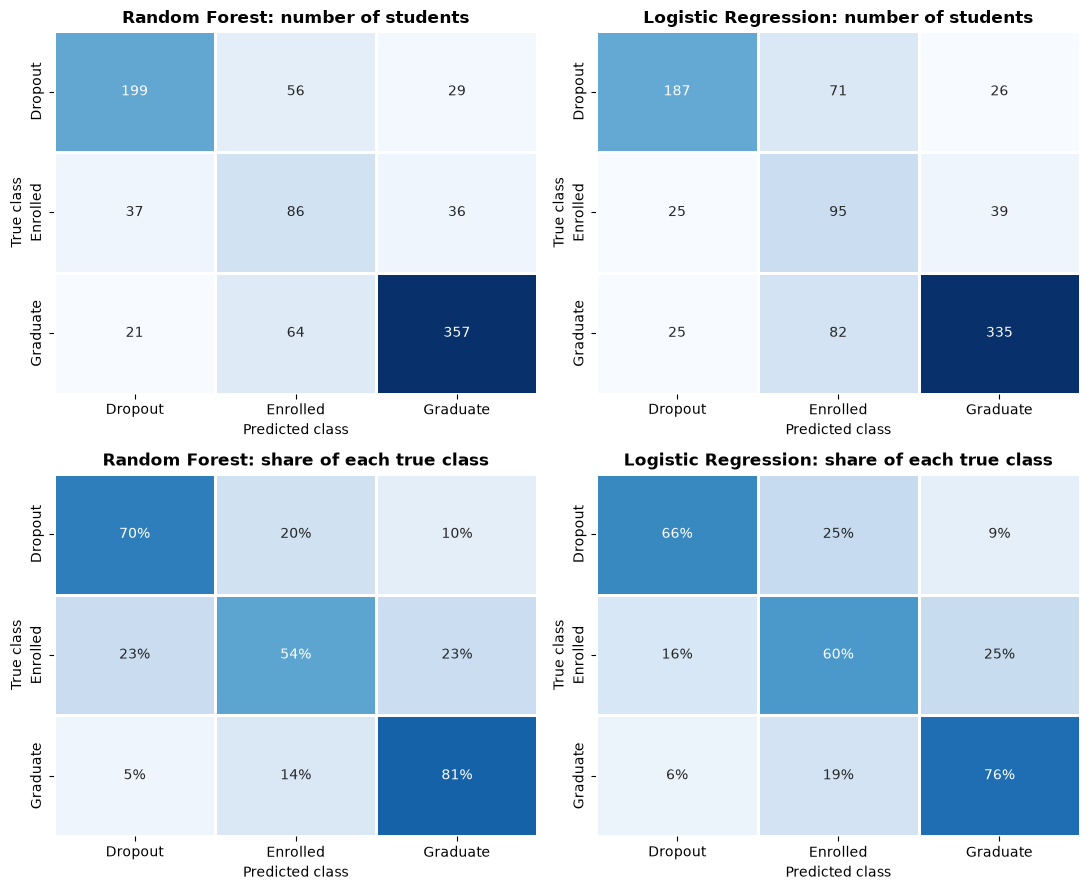

In [9]:
# ---------- Confusion-matrix heatmaps (counts and row-normalised recall) ----------
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for col, (name, res) in enumerate(results.items()):
    cm = res["cm"]
    cm_norm = cm / cm.sum(axis=1, keepdims=True)

    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=2, linecolor="white",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0, col])
    axes[0, col].set_title(f"{name}: number of students")

    sns.heatmap(cm_norm, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, cbar=False,
                linewidths=2, linecolor="white",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1, col])
    axes[1, col].set_title(f"{name}: share of each true class")

for ax in axes.ravel():
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.grid(False)
plt.tight_layout()
plt.savefig(plots_dir / "confusion_matrices_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

pd.concat([
    pd.DataFrame(res["cm"], index=[f"{name} | true {c}" for c in CLASS_NAMES],
                 columns=[f"predicted {c}" for c in CLASS_NAMES])
    for name, res in results.items()
]).to_csv(results_dir / "confusion_matrices.csv")

**What this means:** both models recognise *Graduate* best and *Dropout* reasonably well, but *Enrolled* is correctly identified only a little over half of the time. Most of the damage is in the **Enrolled column**: a large group of Dropout and Graduate students are predicted as Enrolled. Both models make mistakes of the same kind, which suggests the difficulty comes from the data (Enrolled students look like both other groups) and not from the choice of algorithm.

### 3.4 Per-class precision, recall and F1

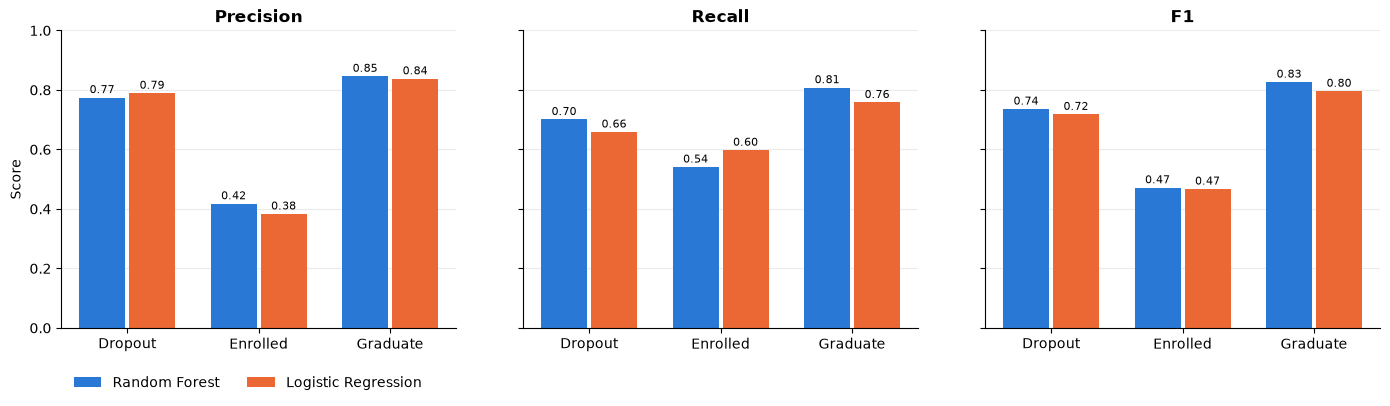

In [10]:
# ---------- Per-class precision / recall / F1, side by side ----------
metrics = ["Precision", "Recall", "F1"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
width = 0.38
x = np.arange(len(CLASS_NAMES))
for ax, metric in zip(axes, metrics):
    for i, (name, res) in enumerate(results.items()):
        vals = res["per_class"][metric].values
        bars = ax.bar(x + (i - 0.5) * width, vals, width * 0.92, color=MODEL_COLORS[name],
                      label=name if metric == "Precision" else None)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.2f}", ha="center", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES)
    ax.set_title(metric); ax.set_ylim(0, 1.0); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Score")
axes[0].legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.12), ncol=2)
plt.tight_layout()
plt.savefig(plots_dir / "per_class_metrics_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**What this means:** *Enrolled* is the weakest class for both models (F1 below 0.5), while *Graduate* is the strongest. Class weighting makes the models willing to predict Enrolled, which keeps its recall roughly between 54% and 60%, but its precision stays low (roughly 4 in 10 predicted Enrolled students really are Enrolled). Logistic Regression has the higher Enrolled recall and Random Forest the higher Enrolled precision, but their Enrolled F1 scores are almost the same.

### 3.5 5-fold cross-validation

Each model, with its tuned settings, is trained and scored on five different train/validation splits of the **training** set. The mean shows the typical performance and the standard deviation shows how much it moves between splits.

                                          Accuracy    Macro Precision       Macro Recall           Macro F1
Model (5-fold CV, mean +/- std)                                                                            
Random Forest                    0.7480 +/- 0.0079  0.7014 +/- 0.0063  0.7003 +/- 0.0085  0.6991 +/- 0.0069
Logistic Regression              0.7256 +/- 0.0122  0.6881 +/- 0.0111  0.6918 +/- 0.0124  0.6846 +/- 0.0114

Macro F1 per fold:
Model  Logistic Regression  Random Forest
Fold                                     
1                   0.6867         0.6961
2                   0.6922         0.6973
3                   0.6983         0.7107
4                   0.6735         0.6990
5                   0.6724         0.6924


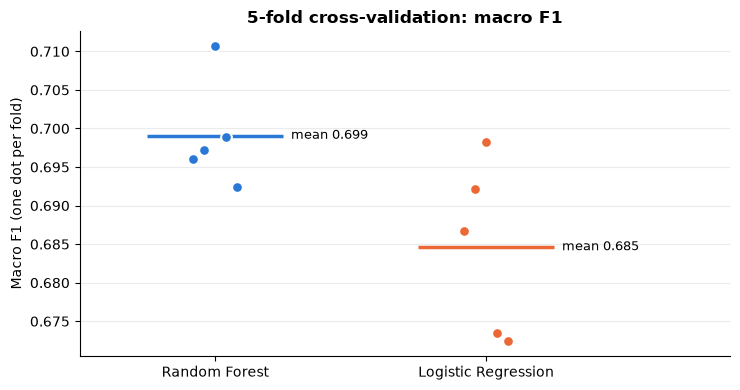

In [11]:
# ---------- 5-fold stratified cross-validation (training set) ----------
cv_folds = pd.concat(
    [cross_validate_model(name, model, X_train, y_train, cv) for name, model in models.items()],
    ignore_index=True,
)
cv_folds.round(4).to_csv(results_dir / "cross_validation_folds.csv", index=False)

cv_metrics = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]
cv_summary = cv_folds.groupby("Model")[cv_metrics].agg(["mean", "std"])
cv_table = pd.DataFrame({
    m: [f"{cv_summary.loc[name, (m, 'mean')]:.4f} +/- {cv_summary.loc[name, (m, 'std')]:.4f}"
        for name in models] for m in cv_metrics
}, index=list(models))
cv_table.index.name = "Model (5-fold CV, mean +/- std)"
cv_table.to_csv(results_dir / "cross_validation_summary.csv")
print(cv_table.to_string())

print("\nMacro F1 per fold:")
print(cv_folds.pivot(index="Fold", columns="Model", values="Macro F1").round(4).to_string())

# Fold-by-fold view: how stable is each model?
fig, ax = plt.subplots(figsize=(7.5, 4))
for i, name in enumerate(models):
    vals = cv_folds.loc[cv_folds["Model"] == name, "Macro F1"].values
    ax.scatter(np.full(len(vals), i) + np.linspace(-0.08, 0.08, len(vals)), vals, s=60,
               color=MODEL_COLORS[name], edgecolor="white", linewidth=1.5, zorder=3)
    ax.hlines(vals.mean(), i - 0.25, i + 0.25, color=MODEL_COLORS[name], linewidth=2.5, zorder=2)
    ax.text(i + 0.28, vals.mean(), f"mean {vals.mean():.3f}", va="center", fontsize=9)
ax.set_xticks(range(len(models))); ax.set_xticklabels(list(models)); ax.set_xlim(-0.5, 1.9)
ax.set_ylabel("Macro F1 (one dot per fold)"); ax.set_title("5-fold cross-validation: macro F1")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.savefig(plots_dir / "cross_validation_macro_f1.png", dpi=150, bbox_inches="tight")
plt.show()

**What this means:** Random Forest has the higher mean macro F1 in cross-validation, which agrees with the ranking on the test set. The standard deviations (printed above) show how much of the gap is within normal fold-to-fold variation. One small caveat: the scaler was fitted on the whole training set during preprocessing, so each validation fold has influenced the scaling slightly; the effect is tiny, and the test-set results are not affected by it.

### 3.6 Misclassification analysis

Which mistakes happen most, who ends up predicted as *Enrolled*, and do the two models fail on the same students? The McNemar test checks whether the accuracy difference between the models is bigger than what chance would produce on the same 885 students.

In [12]:
# ---------- Misclassification analysis ----------
rows = []
for name, res in results.items():
    cm = res["cm"]
    for i, true_cls in enumerate(CLASS_NAMES):
        for j, pred_cls in enumerate(CLASS_NAMES):
            if i != j:
                rows.append({"Model": name, "True class": true_cls, "Predicted as": pred_cls,
                             "Students": int(cm[i, j]),
                             "% of true class": 100 * cm[i, j] / cm[i].sum()})
errors_df = pd.DataFrame(rows).sort_values(["Model", "Students"], ascending=[True, False])
errors_df.round(1).to_csv(results_dir / "misclassification_pairs.csv", index=False)
print("MOST FREQUENT MISTAKES (test set)")
print(errors_df.round(1).to_string(index=False))

# Where do the students PREDICTED as Enrolled really come from? (explains Enrolled precision)
print("\nWHO ENDS UP PREDICTED AS 'ENROLLED'? (true class of those students)")
for name, res in results.items():
    col = res["cm"][:, 1]
    print(f"  {name}: " + ", ".join(f"{CLASS_NAMES[i]} {col[i]} ({col[i]/col.sum():.0%})" for i in range(3)))

# Do the two models fail on the same students?
correct = {name: (res["y_pred"] == y_test.values) for name, res in results.items()}
rf_ok, lr_ok = correct["Random Forest"], correct["Logistic Regression"]
agreement = pd.DataFrame({
    "Students": [int((rf_ok & lr_ok).sum()), int((rf_ok & ~lr_ok).sum()),
                 int((~rf_ok & lr_ok).sum()), int((~rf_ok & ~lr_ok).sum())]},
    index=["Both correct", "Only Random Forest correct", "Only Logistic Regression correct", "Both wrong"])
agreement["% of test set"] = (100 * agreement["Students"] / len(y_test)).round(1)
agreement.to_csv(results_dir / "model_agreement.csv")
print("\nAGREEMENT BETWEEN THE TWO MODELS")
print(agreement.to_string())

# Is the accuracy gap bigger than chance? Exact McNemar test on the disagreements.
only_rf, only_lr = int((rf_ok & ~lr_ok).sum()), int((~rf_ok & lr_ok).sum())
mcnemar_p = binomtest(only_rf, only_rf + only_lr, 0.5).pvalue
print(f"\nExact McNemar test: only-RF-correct = {only_rf}, only-LR-correct = {only_lr}, p-value = {mcnemar_p:.3f}")

MOST FREQUENT MISTAKES (test set)
              Model True class Predicted as  Students  % of true class
Logistic Regression   Graduate     Enrolled        82             18.6
Logistic Regression    Dropout     Enrolled        71             25.0
Logistic Regression   Enrolled     Graduate        39             24.5
Logistic Regression    Dropout     Graduate        26              9.2
Logistic Regression   Enrolled      Dropout        25             15.7
Logistic Regression   Graduate      Dropout        25              5.7
      Random Forest   Graduate     Enrolled        64             14.5
      Random Forest    Dropout     Enrolled        56             19.7
      Random Forest   Enrolled      Dropout        37             23.3
      Random Forest   Enrolled     Graduate        36             22.6
      Random Forest    Dropout     Graduate        29             10.2
      Random Forest   Graduate      Dropout        21              4.8

WHO ENDS UP PREDICTED AS 'ENROLLED'? (true

**What this means:**

- **Pattern:** the largest error groups are Graduate and Dropout students predicted as *Enrolled*, and Enrolled students pushed to the other two classes. Only about 4 in 10 students predicted as Enrolled are truly Enrolled. This is a broader problem than a simple Enrolled-vs-Graduate confusion.
- **Why Enrolled is hard:** an *Enrolled* student is still in the middle of the programme, so the outcome is not decided yet. After one semester such a student can look like a future graduate (good grades) or like a future dropout (weak grades or unpaid fees), and the features cannot separate them cleanly.
- **Same students, same errors:** roughly one in five test students is misclassified by *both* models, and only a small share is classified correctly by one model but not the other. The models disagree on few students, so they learned very similar signals.
- **Is the gap real?** the McNemar result is printed above and summarised in Section 3.8.

### 3.7 Trade-offs: accuracy vs. interpretability vs. computational cost

| Criterion | Random Forest | Logistic Regression |
|---|---|---|
| Predictive performance | Slightly higher (accuracy, macro F1, CV) | Slightly lower, but close |
| Non-linear patterns and feature interactions (for example fees unpaid *and* low approved units) | Learned automatically | Only linear effects unless interactions are engineered |
| Interpretability | Feature-importance ranking (shows *which* features matter, not in which direction) | Signed coefficients (shows direction and strength for each class) |
| Training and prediction cost | Higher, but still seconds (measured below) | Very light |
| Tuning effort | Three hyperparameters (27 combinations) | One hyperparameter (`C`) |
| Sensitivity to feature scaling | None | Needs scaling (already done in preprocessing) |
| Stability across machines/versions | Same result when re-run | Tuned `C` can switch between near-tied values (Section 3.1) |

The next cell measures the computational cost and shows what Logistic Regression can explain about a Dropout prediction.

                     Training time (s)  Prediction time, 885 students (s)  Saved model size (MB)
Model                                                                                           
Random Forest                     1.26                              0.056                   6.58
Logistic Regression               0.54                              0.003                   0.01
(Times depend on the machine; compare the models with each other, not with other computers.)


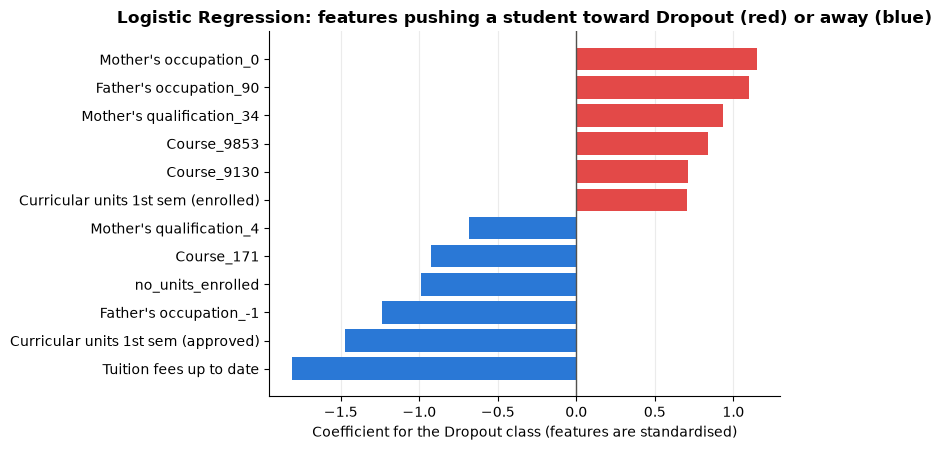


Random Forest top-8 feature importance (importance has no sign/direction):
academic_progress                         0.1345
Curricular units 1st sem (approved)       0.1081
Curricular units 1st sem (grade)          0.0805
Tuition fees up to date                   0.0547
Curricular units 1st sem (evaluations)    0.0500
Admission grade                           0.0417
Age at enrollment                         0.0415
Previous qualification (grade)            0.0324


In [13]:
# ---------- Trade-offs: speed, size, and what each model can explain ----------
def time_it(fn, repeats=3):
    best = float("inf")
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); best = min(best, time.perf_counter() - t0)
    return best

cost_rows = []
for name, model in models.items():
    train_s = time_it(lambda: clone(model).fit(X_train, y_train), repeats=2)
    predict_s = time_it(lambda: model.predict(X_test))
    buf = io.BytesIO(); joblib.dump(model, buf)
    cost_rows.append({"Model": name,
                      "Training time (s)": round(train_s, 2),
                      "Prediction time, 885 students (s)": round(predict_s, 3),
                      "Saved model size (MB)": round(buf.getbuffer().nbytes / 1e6, 2)})
cost_df = pd.DataFrame(cost_rows).set_index("Model")
cost_df.to_csv(results_dir / "computational_cost.csv")
print(cost_df.to_string())
print("(Times depend on the machine; compare the models with each other, not with other computers.)")

# Interpretability evidence for Logistic Regression: signed coefficients for the Dropout class
coef = pd.Series(best_lr.coef_[CLASS_IDS.index(0)], index=X_train.columns)
top = pd.concat([coef.sort_values().head(6), coef.sort_values().tail(6)])
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "#e34948", "#2a78d6"))
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_title("Logistic Regression: features pushing a student toward Dropout (red) or away (blue)")
ax.set_xlabel("Coefficient for the Dropout class (features are standardised)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(plots_dir / "logistic_regression_dropout_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

# Random Forest: global importance (no direction) - top 8
rf_imp = pd.Series(best_rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(8)
print("\nRandom Forest top-8 feature importance (importance has no sign/direction):")
print(rf_imp.round(4).to_string())

**What this means:** both models train and predict in a fraction of a second to a few seconds on this dataset, so computational cost does **not** decide between them here; Random Forest is relatively slower and larger, but both are tiny in absolute terms. The coefficient chart shows what Logistic Regression offers that Random Forest cannot: a direction. Unpaid tuition and fewer approved first-semester units push a student toward Dropout, while being up to date on fees and having more approved units pull away from it. Correlated features share their effect (for example *enrolled* and *approved* units), so individual coefficients should be read together and not one by one. Random Forest's importance ranking points to the same academic and financial drivers (`academic_progress`, approved units, grades, tuition status).

### 3.8 Headline numbers

The next cell prints the key numbers directly from the results above, so the written conclusion always matches the tables.

In [14]:
# ---------- Auto-generated headline numbers (always match the tables above) ----------
best_by_f1 = summary_df["Macro F1"].idxmax()
other = [m for m in summary_df.index if m != best_by_f1][0]
cv_means = cv_folds.groupby("Model")["Macro F1"].mean()
cv_stds = cv_folds.groupby("Model")["Macro F1"].std()

print("KEY NUMBERS FOR THE WRITE-UP")
for name in summary_df.index:
    r = summary_df.loc[name]
    print(f"- {name}: test accuracy {r['Accuracy']:.1%}, test macro F1 {r['Macro F1']:.3f}, "
          f"5-fold CV macro F1 {cv_means[name]:.3f} (std {cv_stds[name]:.3f})")
print(f"- Best test macro F1: {best_by_f1} "
      f"(+{summary_df.loc[best_by_f1, 'Macro F1'] - summary_df.loc[other, 'Macro F1']:.3f} macro F1, "
      f"{(summary_df.loc[best_by_f1, 'Accuracy'] - summary_df.loc[other, 'Accuracy']) * 100:+.1f} accuracy points vs {other})")
print(f"- Best CV macro F1  : {cv_means.idxmax()}")
verdict = "statistically significant" if mcnemar_p < 0.05 else "NOT statistically significant"
print(f"- Accuracy gap on the test set is {verdict} (McNemar p = {mcnemar_p:.3f})")
for name, res in results.items():
    pc = res["per_class"].set_index("Class")
    worst = pc["F1"].idxmin()
    print(f"- {name}: weakest class = {worst} (F1 {pc.loc[worst, 'F1']:.2f}); "
          f"Enrolled precision {pc.loc['Enrolled', 'Precision']:.2f}, Enrolled recall {pc.loc['Enrolled', 'Recall']:.2f}")
    top_err = errors_df[errors_df["Model"] == name].iloc[0]
    print(f"  most common mistake: true {top_err['True class']} predicted as {top_err['Predicted as']} "
          f"({int(top_err['Students'])} students)")

KEY NUMBERS FOR THE WRITE-UP
- Random Forest: test accuracy 72.5%, test macro F1 0.678, 5-fold CV macro F1 0.699 (std 0.007)
- Logistic Regression: test accuracy 69.7%, test macro F1 0.660, 5-fold CV macro F1 0.685 (std 0.011)
- Best test macro F1: Random Forest (+0.018 macro F1, +2.8 accuracy points vs Logistic Regression)
- Best CV macro F1  : Random Forest
- Accuracy gap on the test set is statistically significant (McNemar p = 0.026)
- Random Forest: weakest class = Enrolled (F1 0.47); Enrolled precision 0.42, Enrolled recall 0.54
  most common mistake: true Graduate predicted as Enrolled (64 students)
- Logistic Regression: weakest class = Enrolled (F1 0.47); Enrolled precision 0.38, Enrolled recall 0.60
  most common mistake: true Graduate predicted as Enrolled (82 students)


## 4. Conclusion: Best Model Selection & Reasoning

**Which model performed best?** **Random Forest** performed best overall. It is ahead of Logistic Regression on test accuracy, macro F1 and weighted F1, and it also has the higher mean macro F1 in 5-fold cross-validation (exact numbers in Section 3.8). The advantage is small, so it should be read as "slightly better", not "much better": both models are limited by the same difficulty, which is separating *Enrolled* students.

**Why does Random Forest do a bit better?** Student outcomes depend on combinations of factors (for example unpaid fees together with few approved units), and a forest of decision trees can learn such interactions and non-linear thresholds without manual feature engineering. Logistic Regression draws one linear boundary per class and cannot capture these combinations unless they are added by hand.

**Recommendation for the final system: Random Forest**, for these reasons:

1. **Best and consistent performance:** it comes out ahead on the test set *and* in cross-validation, not on just one of them.
2. **Fits the Phase 2 requirements:** it provides class probabilities (for the dashboard's prediction-confidence display and scenario sliders) and feature importances (for the key-driver chart).
3. **Cost is acceptable:** training and prediction take seconds, and the saved model is a few megabytes.
4. **Reproducible:** with a fixed `random_state` and the library versions used for this run, re-running it gives the same result, which matters for a dashboard that must behave consistently.
**What we give up:** Random Forest is less transparent than Logistic Regression. To compensate, we keep Logistic Regression as a **baseline and explanation companion** (its signed coefficients tell advisors which direction each factor pushes a student), and in Phase 2 we can add permutation importance or SHAP values to explain individual Random Forest predictions.

**Limitations to keep in mind:**

- *Enrolled* remains the weak class for both models (F1 below 0.5), so the advisory system should present Enrolled predictions with lower confidence and rely mainly on the more reliable Dropout and Graduate signals.
- Predicting after the first semester is a deliberate design choice for early warning; it also makes the task harder than predicting with second-semester data.
- The test set has 885 students. The accuracy gap between the models (about 3 percentage points) is statistically significant according to the McNemar test, but it is small in practical terms, and smaller differences (such as the macro F1 gap of about 0.02) may still be within normal sampling variation.
- The hyperparameter grids are small, and decision thresholds were not tuned.

## 5. Next Steps for Phase 2 Integration

1. **Unsupervised learning (Phase 2, Part A):** remove `Target`, scale the features, and apply at least two clustering algorithms (for example K-Means and a hierarchical or density-based method). Evaluate with Silhouette, Davies-Bouldin, WCSS, and BCubed precision/recall using the known outcome classes as ground truth. Then test whether adding the cluster label as an extra feature helps Random Forest, especially for *Enrolled*, and use cluster profiles to describe student groups to advisors.
2. **Improve the weak class:** try probability calibration and decision-threshold tuning for *Enrolled*, and (as optional experiments) resampling inside the cross-validation loop or a boosted-tree model, comparing every change with the same evaluation function used here.
3. **Generative AI briefings (Part B):** pass each student's predicted class, class probabilities, top drivers, and cluster profile into prompt templates so the model writes an advisor-ready summary. `test_predictions.csv` (saved below) provides ready-made example cases.
4. **Executive dashboard (Part C):** load the saved Random Forest, expose scenario sliders for key inputs (approved units, grades, tuition status, scholarship), show the predicted class with its probability as the confidence metric, and display the key-driver chart.
5. **Engineering needed for the dashboard:** the saved model expects the 102 *preprocessed* columns. The fitted preprocessing objects (rare-category grouping, one-hot encoder, scaler) must also be saved, ideally together with the model in one scikit-learn `Pipeline`, so the dashboard can accept raw student inputs. We also recommend adding a `requirements.txt` with library versions so results are reproducible on every machine.

### Saving artifacts for Phase 2

This cell saves the tuned models and the test-set predictions (with probabilities) into the `Supervised_Learning/` folders required by the project structure.

In [15]:
# ---------- Save the final models for Phase 2 (dashboard / GenAI briefings) ----------
joblib.dump(best_rf, models_dir / "random_forest_tuned.joblib", compress=3)
joblib.dump(best_lr, models_dir / "logistic_regression_tuned.joblib", compress=3)

# Test-set predictions with class probabilities (Phase 2 can use them for confidence metrics)
pred_out = pd.DataFrame({"true_class": [CLASS_NAMES[i] for i in y_test.values]}, index=y_test.index)
for name, res in results.items():
    key = name.lower().replace(" ", "_")
    pred_out[f"{key}_prediction"] = [CLASS_NAMES[i] for i in res["y_pred"]]
    for k, cname in enumerate(CLASS_NAMES):
        pred_out[f"{key}_proba_{cname.lower()}"] = res["proba"][:, k].round(4)
pred_out.to_csv(results_dir / "test_predictions.csv")

for p in sorted(Path("Supervised_Learning").rglob("*")):
    if p.is_file():
        print(f"{str(p):75s} {p.stat().st_size/1e6:6.2f} MB")

Supervised_Learning\evaluation_results\computational_cost.csv                 0.00 MB
Supervised_Learning\evaluation_results\confusion_matrices.csv                 0.00 MB
Supervised_Learning\evaluation_results\cross_validation_folds.csv             0.00 MB
Supervised_Learning\evaluation_results\cross_validation_summary.csv           0.00 MB
Supervised_Learning\evaluation_results\misclassification_pairs.csv            0.00 MB
Supervised_Learning\evaluation_results\model_agreement.csv                    0.00 MB
Supervised_Learning\evaluation_results\test_metrics_per_class.csv             0.00 MB
Supervised_Learning\evaluation_results\test_metrics_summary.csv               0.00 MB
Supervised_Learning\evaluation_results\test_predictions.csv                   0.06 MB
Supervised_Learning\models\logistic_regression_tuned.joblib                   0.00 MB
Supervised_Learning\models\random_forest_tuned.joblib                         1.70 MB
Supervised_Learning\plots\confusion_matrices_compariso